[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C08/E08-3_Injection_Plastique_CORRIGE.ipynb)

# Défauts de pièces moulées : classer avec un ensemble de modèles

## Le contexte

Une presse à injecter produit un boîtier plastique. Pour chaque pièce, le relevé de production donne la matière (PP, ABS ou PA66), la température du fondu, l'écart de température entre les deux demi-moules, la pression d'injection, la pression et le temps de maintien, et la force de fermeture de la presse. À l'inspection, la pièce est conforme ou porte un défaut dominant : pièce incomplète, bavure, retassure ou gauchissement. Chaque défaut a sa cause, et aucune règle simple ne les couvre tous. Le service production voudrait prévoir le défaut dominant d'après les réglages, avant de lancer la série.

La grandeur à prédire est un état parmi cinq : c'est un problème de classification multiclasse.

Défi : prédire `type_defaut` et obtenir un F-score macro supérieur à celui du modèle de départ sur la base de test. Ce modèle de départ est un AdaBoost aux réglages par défaut, qui corrige ses erreurs pas à pas avec des arbres à une seule question ; il atteint un F-score macro de 0,717 : à vous de faire mieux, avec un boosting plus riche, un vote ou un empilement de modèles. La règle de découpage est fixée plus bas. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-Injection_Plastique.xlsx`, dans le dossier `donnees` du dépôt : 1 000 pièces, 8 colonnes. Une ligne est une pièce moulée.

| Colonne | Signification | Unité |
|---|---|---|
| `matiere` | matière injectée : `PP`, `ABS` ou `PA66` | catégorie |
| `temperature_fusion_C` | température du fondu à l'injection | °C |
| `ecart_temperature_moule_C` | température du demi-moule fixe moins celle du demi-moule mobile | °C |
| `pression_injection_MPa` | pression d'injection | MPa |
| `pression_maintien_MPa` | pression de maintien | MPa |
| `temps_maintien_s` | durée du maintien en pression | s |
| `force_fermeture_kN` | force de fermeture de la presse | kN |
| `type_defaut` | cible : défaut dominant, `conforme`, `incomplete`, `bavure`, `retassure` ou `gauchissement` | catégorie |

Origine : jeu simulé, d'après les mécanismes du moulage par injection : remplissage, ouverture du moule sous la pression en cavité, maintien et refroidissement dissymétrique. Quelques températures du fondu et temps de maintien ne sont pas relevés. Il enseigne une méthode, et aucune conclusion de production n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides et la répartition des cinq états avant toute modélisation : la forme d'un fichier se lit sur le fichier entier. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Injection_Plastique.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Injection_Plastique.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "type_defaut"
print("dimensions :", df.shape)
vides = df.isna().sum()
print("cases vides :", vides[vides > 0].to_dict())
parts = (100 * df[cible].value_counts(normalize=True)).round(1)
print(parts.to_dict())
df.head(3)

dimensions : (1000, 8)
cases vides : {'temperature_fusion_C': 28, 'temps_maintien_s': 25}
{'conforme': 34.0, 'bavure': 27.6, 'incomplete': 16.6, 'gauchissement': 10.9, 'retassure': 10.9}


,matiere,temperature_fusion_C,ecart_temperature_moule_C,pression_injection_MPa,pression_maintien_MPa,temps_maintien_s,force_fermeture_kN,type_defaut
0,ABS,224.0,6.5,58,61,6.9,450,incomplete
1,PP,213.0,-0.5,61,56,3.7,420,incomplete
2,ABS,248.0,-1.5,137,32,3.7,490,bavure


Lecture du résultat : 1 000 pièces, 8 colonnes. La température du fondu compte 28 cases vides et le temps de maintien 25, qu'il faudra remplir. Les pièces conformes forment la classe la plus nombreuse (34,0 %), et les quatre défauts pèsent de 10,9 % à 27,6 % des pièces : aucune classe n'est négligeable.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Injection_Plastique.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : mettre le test de côté

Un quart des pièces est mis de côté avant tout apprentissage, tout réglage et toute comparaison avec la cible. La graine 42 fixe le tirage : chacun obtient la même base de test, et les scores se comparent. Le tirage est stratifié, pour que chaque état soit représenté dans les deux bases dans la même proportion.

In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=cible)
y = df[cible]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=GRAINE, stratify=y)
print("apprentissage :", len(X_train), "pièces")
print("test :", len(X_test), "pièces")

apprentissage : 750 pièces
test : 250 pièces


### Étape 3 : regarder l'écart des demi-moules sur l'apprentissage

Les causes ne se ressemblent pas. Pour en voir une, la figure place l'écart de température entre les demi-moules de chaque pièce d'apprentissage, état par état, et le tableau donne la part des pièces dont cet écart dépasse 6 °C en valeur absolue.

type_defaut
bavure           22.0
conforme          0.0
gauchissement    95.0
incomplete       19.0
retassure        22.0


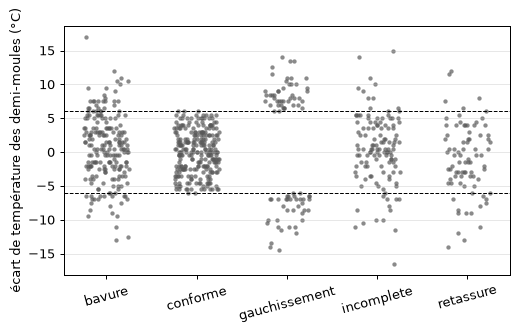

In [3]:
classes = sorted(y_train.unique())
ecart = X_train["ecart_temperature_moule_C"]
hasard = np.random.default_rng(GRAINE)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for k, etat in enumerate(classes):
    valeurs = ecart[y_train == etat]
    ax.scatter(k + hasard.uniform(-0.25, 0.25, len(valeurs)), valeurs, s=12, color="0.35", linewidth=0, alpha=0.7)
ax.axhline(6, color="black", linewidth=0.8, linestyle="--")
ax.axhline(-6, color="black", linewidth=0.8, linestyle="--")
ax.set(xticks=range(len(classes)), ylabel="écart de température des demi-moules (°C)")
ax.set_xticklabels(classes, rotation=15)
ax.grid(alpha=0.3, axis="y")
plt.show()
part_hors_6 = (ecart.abs() > 6).groupby(y_train).mean().round(2)
print((100 * part_hors_6).to_string())

Lecture du résultat : 95 % des pièces à gauchissement ont un écart supérieur à 6 °C en valeur absolue, de l'un ou l'autre signe, alors que les pièces conformes n'en ont aucune (0 %). Cette limite est double : elle ne se résume pas à un seuil sur la valeur de la colonne, et un modèle qui trace des frontières planes la manque. Les autres défauts ont d'autres causes, qui ne se lisent pas toutes sur une colonne.

### Étape 4 : construire le modèle de départ

Le modèle de départ est celui de la section du livre : un AdaBoost, qui entraîne des arbres à une seule question l'un après l'autre, chacun donnant plus de poids aux pièces que les précédents ont mal classées. Il garde ses réglages par défaut, avec une graine fixée. La matière est encodée en colonnes 0 ou 1 et les cases vides sont remplies par la médiane de l'apprentissage. Il apprend sur `X_train` seul.

In [4]:
# Solution :
from sklearn.compose import make_column_transformer
from sklearn.ensemble import AdaBoostClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = make_column_transformer(
    (OneHotEncoder(), ["matiere"]), remainder=SimpleImputer(strategy="median"))
modele = make_pipeline(preprocessor, AdaBoostClassifier(random_state=GRAINE))
modele.fit(X_train, y_train)
# Fin de la solution

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=SimpleImputer(strategy='median'),
                                   transformers=[('onehotencoder',
                                                  OneHotEncoder(),
                                                  ['matiere'])])),
                ('adaboostclassifier', AdaBoostClassifier(random_state=42))])

### Étape 5 : mesurer sur la base de test

Le modèle prédit les pièces qu'il n'a jamais vues. On lit le F-score macro, l'exactitude et le F-score de chaque état. Un témoin sans apprentissage, qui répond toujours l'état le plus fréquent, donne le point de comparaison le plus bas.

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

y_pred = modele.predict(X_test)
score_depart = f1_score(y_test, y_pred, average="macro")
temoin = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
score_temoin = f1_score(y_test, temoin.predict(X_test), average="macro")
print(f"F-score macro : {score_depart:.3f}")
print(f"exactitude : {accuracy_score(y_test, y_pred):.3f}")
print(f"F-score macro du témoin (toujours l'état le plus fréquent) : {score_temoin:.3f}")
f_etats = pd.Series(f1_score(y_test, y_pred, average=None, labels=classes), index=classes)
print(f_etats.round(3).to_string())

F-score macro : 0.717
exactitude : 0.756
F-score macro du témoin (toujours l'état le plus fréquent) : 0.101
bavure           0.850
conforme         0.782
gauchissement    0.731
incomplete       0.723
retassure        0.500


Lecture du résultat : le F-score macro est de 0,717 pour une exactitude de 0,756, très au-dessus du témoin (0,101). Le F-score le plus bas est celui de l'état `retassure` (0,500), le plus haut celui de l'état `bavure` (0,850). C'est ce chiffre, mesuré sur des pièces que le modèle n'a jamais vues, que l'on a le droit d'annoncer.

## Pour aller plus loin : boosting plus riche, vote, empilement

Le modèle de départ de l'étape 4 reste le score de référence du défi. Les deux cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. La première prédit l'apprentissage par validation croisée avec trois modèles de familles différentes, une régression logistique, une machine à vecteurs de support et une forêt, puis avec les ensembles : gradient boosting, gradient boosting par histogrammes, vote souple et empilement de ces trois modèles. Le tableau donne le F-score de chaque état : il montre ce que chaque modèle voit et manque. La seconde mesure l'ensemble retenu, parmi les ensembles, une seule fois sur le test. Les valeurs sont lues dans les sorties imprimées.

In [6]:
# Solution :
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.svm import SVC

a_l_echelle = make_column_transformer(
    (OneHotEncoder(), ["matiere"]), remainder=make_pipeline(SimpleImputer(strategy="median"), StandardScaler()))
base = [("logistique", make_pipeline(a_l_echelle, LogisticRegression(max_iter=2000))),
        ("svm", make_pipeline(a_l_echelle, CalibratedClassifierCV(SVC(C=10), ensemble=False))),
        ("forêt", make_pipeline(preprocessor, RandomForestClassifier(n_estimators=200, random_state=GRAINE)))]
ensembles = {
    "départ : AdaBoost": modele,
    "gradient boosting": make_pipeline(preprocessor, GradientBoostingClassifier(random_state=GRAINE)),
    "gradient boosting par histogrammes": make_pipeline(preprocessor, HistGradientBoostingClassifier(random_state=GRAINE)),
    "vote souple": VotingClassifier(base, voting="soft"),
    "empilement": StackingClassifier(base, final_estimator=LogisticRegression(max_iter=2000), cv=5)}
plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
f1_classes, notes_cv = {}, {}
for nom, pipeline in base + list(ensembles.items()):
    pred_cv = cross_val_predict(pipeline, X_train, y_train, cv=plis)
    f1_classes[nom] = f1_score(y_train, pred_cv, average=None, labels=classes)
    notes_cv[nom] = f1_score(y_train, pred_cv, average="macro")
print(pd.DataFrame(f1_classes, index=classes).round(2).T.to_string())
for nom, note in notes_cv.items():
    print(f"{nom} : F-score macro {note:.3f} en validation croisée")
nom_retenu = max(ensembles, key=notes_cv.get)
print("ensemble retenu par la validation croisée :", nom_retenu)
# Fin de la solution

                                    bavure  conforme  gauchissement  incomplete  retassure
logistique                            0.95      0.79           0.00        0.87       0.79
svm                                   0.89      0.85           0.69        0.75       0.71
forêt                                 0.90      0.85           0.82        0.73       0.71
départ : AdaBoost                     0.84      0.79           0.77        0.57       0.60
gradient boosting                     0.90      0.87           0.88        0.83       0.75
gradient boosting par histogrammes    0.93      0.89           0.86        0.87       0.77
vote souple                           0.92      0.88           0.77        0.81       0.76
empilement                            0.94      0.91           0.86        0.87       0.76
logistique : F-score macro 0.679 en validation croisée
svm : F-score macro 0.776 en validation croisée
forêt : F-score macro 0.801 en validation croisée
départ : AdaBoost : F-score 

In [7]:
# Solution :
retenu = ensembles[nom_retenu].fit(X_train, y_train)
y_retenu = retenu.predict(X_test)
f1_retenu = f1_score(y_test, y_retenu, average="macro")
print(f"{nom_retenu}, mesuré une fois sur le test : F-score macro {f1_retenu:.3f}")
print(f"gain sur le modèle de départ : {f1_retenu - score_depart:+.3f}")
print(pd.Series(f1_score(y_test, y_retenu, average=None, labels=classes), index=classes).round(3).to_string())
# Fin de la solution

empilement, mesuré une fois sur le test : F-score macro 0.842
gain sur le modèle de départ : +0.125
bavure           0.873
conforme         0.872
gauchissement    0.800
incomplete       0.857
retassure        0.808


## Le score de référence

Le score publié est le F-score macro du modèle de départ de l'étape 4 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [8]:
import hashlib

score = f1_score(y_test, modele.predict(X_test), average="macro")
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE f1_macro = %.3f" % score)

EMPREINTE_TEST = 0d03b9b205365ebf1a81ffb1ee72d4088e0c8267e1776c65f4a6dba487c0dd22
SCORE_REFERENCE f1_macro = 0.717


## Synthèse

1. Un boosting entraîne des modèles faibles l'un après l'autre, chacun corrigeant les erreurs des précédents ; avec des arbres à une seule question, il ne combine pas plusieurs colonnes dans une même règle, et des arbres plus profonds le font.
2. Le gradient boosting suit la même idée avec une fonction de perte : chaque arbre ajusté corrige le résidu de l'ensemble, et la version par histogrammes accélère le calcul sur de grands jeux.
3. Un vote fait décider plusieurs modèles de familles différentes, un empilement apprend à les pondérer avec un modèle final : ils gagnent quand chaque modèle voit ce que les autres manquent, ce que le tableau des F-scores par état permet de vérifier.
4. Les modèles d'un ensemble se jugent par validation croisée sur l'apprentissage, état par état avant le score global ; l'empilement apprend ses pondérations sur des prédictions faites hors de l'échantillon d'apprentissage de chaque modèle.
5. Le test ne sert qu'une fois, à l'ensemble retenu.